# Lab 1 — rozwiązania

Dane: pliki `.parquet` w folderze `data` (zbiór [private_instagram](https://huggingface.co/datasets/vargr/private_instagram/tree/refs%2Fconvert%2Fparquet/default/train)).

**Zadanie 1.** Wczytaj pliki, scal je w jedną ramkę, sprawdź typy i zmierz pamięć RAM przy domyślnych typach.

In [20]:
import os
import pandas as pd


def sizeof_fmt(num, suffix="B"):
    for unit in ("", "Ki", "Mi", "Gi", "Ti", "Pi", "Ei", "Zi"):
        if abs(num) < 1024.0:
            return f"{num:3.1f}{unit}{suffix}"
        num /= 1024.0
    return f"{num:.1f}Yi{suffix}"


data_dir = "data"
files = sorted(f for f in os.listdir(data_dir) if f.endswith(".parquet"))
frames = [pd.read_parquet(os.path.join(data_dir, f)) for f in files]
df1 = pd.concat(frames, ignore_index=True)

print("pliki:", files)
print("kształt:", df1.shape)
df1.info()
df1.describe()
print("pamięć RAM:", sizeof_fmt(df1.memory_usage(deep=True).sum()))
for column in df1.columns:
    print(f"{column}: {sizeof_fmt(df1[column].memory_usage(deep=True))} ({df1[column].dtype})")

pliki: ['0000.parquet', '0001.parquet']
kształt: (2294716, 17)
<class 'pandas.DataFrame'>
RangeIndex: 2294716 entries, 0 to 2294715
Data columns (total 17 columns):
 #   Column               Dtype
---  ------               -----
 0   sid                  int64
 1   sid_profile          int64
 2   post_id              str  
 3   profile_id           int64
 4   date                 str  
 5   post_type            int64
 6   description          str  
 7   likes                int64
 8   comments             int64
 9   username             str  
 10  bio                  str  
 11  following            int64
 12  followers            int64
 13  num_posts            int64
 14  is_business_account  bool 
 15  lang                 str  
 16  category             str  
dtypes: bool(1), int64(9), str(7)
memory usage: 1.0 GB
pamięć RAM: 1.0GiB
sid: 17.5MiB (int64)
sid_profile: 17.5MiB (int64)
post_id: 41.5MiB (str)
profile_id: 17.5MiB (int64)
date: 59.1MiB (str)
post_type: 17.5MiB (int64)
descr

**Zadanie 2.** Dobierz ciaśniejsze typy danych, zmierz pamięć jeszcze raz i porównaj obie wielkości na wykresie.

przed: 1.0GiB
po: 882.4MiB
<class 'pandas.DataFrame'>
RangeIndex: 2294716 entries, 0 to 2294715
Data columns (total 17 columns):
 #   Column               Dtype         
---  ------               -----         
 0   sid                  uint32        
 1   sid_profile          int32         
 2   post_id              str           
 3   profile_id           uint64        
 4   date                 datetime64[us]
 5   post_type            uint8         
 6   description          str           
 7   likes                uint32        
 8   comments             uint32        
 9   username             str           
 10  bio                  str           
 11  following            uint32        
 12  followers            uint32        
 13  num_posts            uint32        
 14  is_business_account  bool          
 15  lang                 category      
 16  category             category      
dtypes: bool(1), category(2), datetime64[us](1), int32(1), str(4), uint32(6), uint64(1), uin

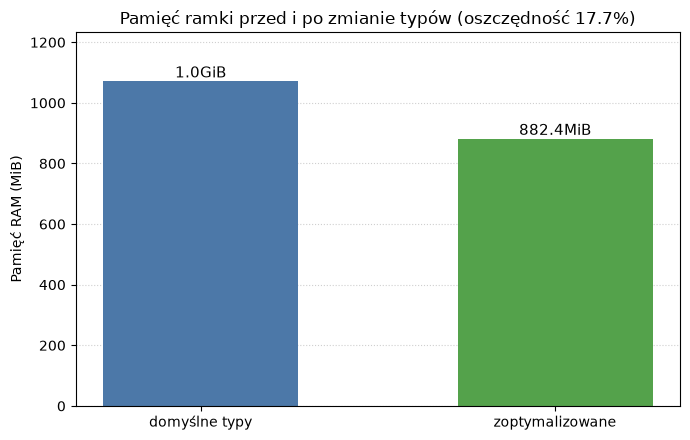

In [21]:
import numpy as np
import matplotlib.pyplot as plt

mem_przed = df1.memory_usage(deep=True).sum()

df2 = df1.astype({
    "sid": np.uint32,
    "sid_profile": np.int32,
    "profile_id": np.uint64,
    "post_type": np.uint8,
    "likes": np.uint32,
    "comments": np.uint32,
    "following": np.uint32,
    "followers": np.uint32,
    "num_posts": np.uint32,
    "lang": "category",
    "category": "category",
}).copy()
df2["date"] = pd.to_datetime(df1["date"])

mem_po = df2.memory_usage(deep=True).sum()
print("przed:", sizeof_fmt(mem_przed))
print("po:", sizeof_fmt(mem_po))
df2.info()

etykiety = ["domyślne typy", "zoptymalizowane"]
wartosci_mib = [mem_przed / 1024**2, mem_po / 1024**2]
roznica = (mem_przed - mem_po) / mem_przed * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(etykiety, wartosci_mib, width=0.55, color=["#4C78A8", "#54A24B"])
ax.set_ylabel("Pamięć RAM (MiB)")
ax.set_title(f"Pamięć ramki przed i po zmianie typów (oszczędność {roznica:.1f}%)")
ax.set_ylim(0, max(wartosci_mib) * 1.15)
ax.yaxis.grid(True, linestyle=":", alpha=0.6)
ax.set_axisbelow(True)

for bar, bajty in zip(bars, (mem_przed, mem_po)):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        sizeof_fmt(bajty),
        ha="center",
        va="bottom",
        fontsize=11,
    )

fig.tight_layout()
plt.show()

**Zadanie 3.** Trzy operacje na całej ramce. Czas mierzymy osobno na danych oryginalnych (`df1`) i zoptymalizowanych (`df2`).

In [12]:
from datetime import datetime

operacje = {
    "grupowanie: średnia likes wg category": lambda df: df.groupby("category", observed=True)["likes"].mean(),
    "filtrowanie: konta firmowe z followers > 10000": lambda df: df.loc[(df["is_business_account"]) & (df["followers"] > 10_000)],
    "agregacja: suma comments wg post_type": lambda df: df.groupby("post_type")["comments"].sum(),
}

def zmierz(df, fn):
    start = datetime.now()
    wynik = fn(df)
    _ = len(wynik)
    return datetime.now() - start

czasy = []
for nazwa, fn in operacje.items():
    czasy.append({
        "operacja": nazwa,
        "oryginalne": zmierz(df1, fn),
        "zoptymalizowane": zmierz(df2, fn),
    })

pd.DataFrame(czasy)

,operacja,oryginalne,zoptymalizowane
0,grupowanie: średnia likes wg category,0 days 00:00:00.126966,0 days 00:00:00.033257
1,filtrowanie: konta firmowe z followers > 10000,0 days 00:00:00.202989,0 days 00:00:00.125751
2,agregacja: suma comments wg post_type,0 days 00:00:00.025173,0 days 00:00:00.027914


**Zadanie 4.** Zapis ramki do CSV (nagłówki kolumn, bez indeksu). Wielkość pliku CSV porównaj w eksploratorze z sumą plików `.parquet` w folderze `data`.

In [14]:
df2.to_csv("instagram.csv", header=True, index=False)

**Zadanie 5.** 

In [19]:
import os
import subprocess
import sys

# Kernel na Windowsie czasem czyta ścieżkę z polskimi znakami jako cp1250 zamiast UTF-8.
katalog = os.getcwd()
try:
    katalog = katalog.encode("cp1250").decode("utf-8")
except (UnicodeEncodeError, UnicodeDecodeError):
    pass

wynik = subprocess.run(
    [sys.executable, os.path.join(katalog, "zadanie5_wczytanie.py")],
    cwd=katalog,
    capture_output=True,
    text=True,
    encoding="utf-8",
    env={**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONUTF8": "1"},
)
print(wynik.stdout)
if wynik.returncode != 0:
    print(wynik.stderr)

Czas wykonania read_file_1: 0:00:13.975761 sekund
wierszy: 2294716
chunksize=100000
Czas wykonania read_file_2: 0:00:13.909327 sekund
wierszy: 2294716
chunksize=500000
Czas wykonania read_file_2: 0:00:13.708516 sekund
wierszy: 2294716
plików: 29, procesów: 14
Czas wczytania multiprocessing: 0:00:04.230615 sekund, wierszy: 2294716
plików: 29, procesów: 28
Czas wczytania multiprocessing: 0:00:05.262468 sekund, wierszy: 2294716

